# 🔒 Ridge Regression from Scratch

**Goal:** Extend Linear Regression with an L2 penalty that discourages large weights, reducing overfitting.

---

## 1. Algorithm Intuition

Plain Linear Regression minimises only the data fit term. When there are many features (or correlated features), some weights can grow very large and overfit. **Ridge Regression** adds a regularisation term that penalises large weights:

$$J(\mathbf{w}, b) = \underbrace{\frac{1}{2m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})^2}_{\text{MSE}} + \underbrace{\frac{\lambda}{2m} \sum_{j=1}^{n} w_j^2}_{\text{L2 penalty}}$$

The bias $b$ is **not** penalised by convention.

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $\lambda$ (`lambda_`) | regularisation strength — larger = stronger shrinkage |
| $m$ | number of training examples |
| $n$ | number of features |
| $\alpha$ | learning rate |
| `num_iters` | gradient-descent iterations |
| `J_history` | regularised cost per iteration |

---

## 2. Regularised Gradient Update

$$\frac{\partial J}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)}) x_j^{(i)} + \frac{\lambda}{m} w_j$$

In matrix form:

$$\frac{\partial J}{\partial \mathbf{w}} = \frac{1}{m} X^T (\hat{y} - y) + \frac{\lambda}{m} \mathbf{w}$$

$$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}^{(i)} - y^{(i)})$$

The update for $\mathbf{w}$ can be rewritten as a **weight decay**:

$$\mathbf{w} := \mathbf{w} \left(1 - \alpha \frac{\lambda}{m}\right) - \frac{\alpha}{m} X^T (\hat{y} - y)$$


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(7)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Data — Many Noisy Features

We create a dataset with 20 features but only a few truly informative ones. This is where Ridge shines.

In [2]:
m = 200   # examples
n = 20    # features (only first 5 are truly relevant)

X_all = np.random.randn(m, n)

# True weights: first 5 non-zero, rest are noise
true_w = np.array([3.0, -2.0, 1.5, -1.0, 2.0] + [0.0] * 15)
true_b = 1.0
y_all  = X_all @ true_w + true_b + np.random.randn(m) * 1.5

print(f"X shape: {X_all.shape}, y shape: {y_all.shape}")

X shape: (200, 20), y shape: (200,)


## 5. Train / Test Split and Normalisation

In [3]:
def train_test_split(X, y, test_ratio=0.2, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

def normalize(X_train, X_test):
    mu    = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1
    return (X_train - mu) / sigma, (X_test - mu) / sigma

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
X_train_n, X_test_n = normalize(X_train, X_test)
print(f"Train: {X_train_n.shape}, Test: {X_test_n.shape}")

Train: (160, 20), Test: (40, 20)


## 6. Ridge Cost Function

In [4]:
def compute_cost_ridge(X, y, w, b, lambda_):
    """
    Regularised MSE cost:
      J = (1/2m) * ||y_hat - y||^2  +  (lambda / 2m) * ||w||^2

    Note: b is NOT regularised.
    """
    m = X.shape[0]
    errors = X @ w + b - y
    mse_term  = np.sum(errors ** 2) / (2 * m)
    reg_term  = (lambda_ / (2 * m)) * np.sum(w ** 2)
    return mse_term + reg_term

## 7. Ridge Gradient Computation

In [5]:
def compute_gradient_ridge(X, y, w, b, lambda_):
    """
    Gradients for Ridge Regression.

    dJ/dw = (1/m) * X^T @ (y_hat - y)  +  (lambda/m) * w
    dJ/db = (1/m) * sum(y_hat - y)   [bias is NOT regularised]
    """
    m = X.shape[0]
    errors = X @ w + b - y         # shape (m,)

    dw = (X.T @ errors) / m  +  (lambda_ / m) * w
    db = np.sum(errors) / m
    return dw, db

## 8. Gradient Descent with Ridge Regularisation

In [6]:
def gradient_descent_ridge(X, y, alpha, num_iters, lambda_):
    """
    Ridge regression gradient descent.

    Parameters
    ----------
    X        : ndarray (m, n)
    y        : ndarray (m,)
    alpha    : float — learning rate
    num_iters: int   — iterations
    lambda_  : float — regularisation strength

    Returns
    -------
    w, b, J_history
    """
    n = X.shape[1]
    w = np.zeros(n)
    b = 0.0
    J_history = []

    for i in range(num_iters):
        dw, db = compute_gradient_ridge(X, y, w, b, lambda_)
        w = w - alpha * dw
        b = b - alpha * db
        J_history.append(compute_cost_ridge(X, y, w, b, lambda_))

        if i % 500 == 0:
            print(f"Iter {i:5d} | Cost: {J_history[-1]:.4f}")

    return w, b, J_history

## 9. Train — Ridge vs. Plain Linear Regression

In [7]:
alpha     = 0.1
num_iters = 3000

# --- Plain Linear Regression (lambda = 0) ---
print("=== Plain Linear Regression ===")
w_plain, b_plain, J_plain = gradient_descent_ridge(
    X_train_n, y_train, alpha, num_iters, lambda_=0.0)

print("\n=== Ridge Regression (lambda = 10) ===")
w_ridge, b_ridge, J_ridge = gradient_descent_ridge(
    X_train_n, y_train, alpha, num_iters, lambda_=10.0)

=== Plain Linear Regression ===
Iter     0 | Cost: 9.1669
Iter   500 | Cost: 1.1091
Iter  1000 | Cost: 1.1091
Iter  1500 | Cost: 1.1091
Iter  2000 | Cost: 1.1091
Iter  2500 | Cost: 1.1091

=== Ridge Regression (lambda = 10) ===
Iter     0 | Cost: 9.1726
Iter   500 | Cost: 1.7426
Iter  1000 | Cost: 1.7426
Iter  1500 | Cost: 1.7426
Iter  2000 | Cost: 1.7426
Iter  2500 | Cost: 1.7426


## 10. Cost History

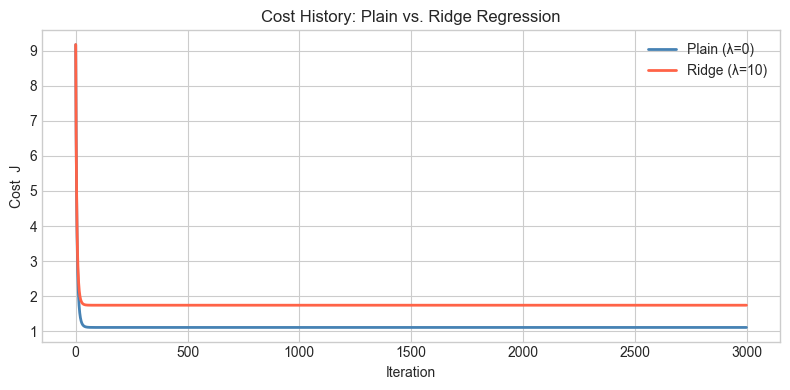

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(J_plain, label='Plain (λ=0)',  color='steelblue', linewidth=2)
ax.plot(J_ridge, label='Ridge (λ=10)', color='tomato',    linewidth=2)
ax.set_xlabel('Iteration')
ax.set_ylabel('Cost  J')
ax.set_title('Cost History: Plain vs. Ridge Regression')
ax.legend()
plt.tight_layout()
plt.show()

## 11. Learned Weights Comparison

We expect Ridge to shrink weights, especially the irrelevant ones (indices 5–19).

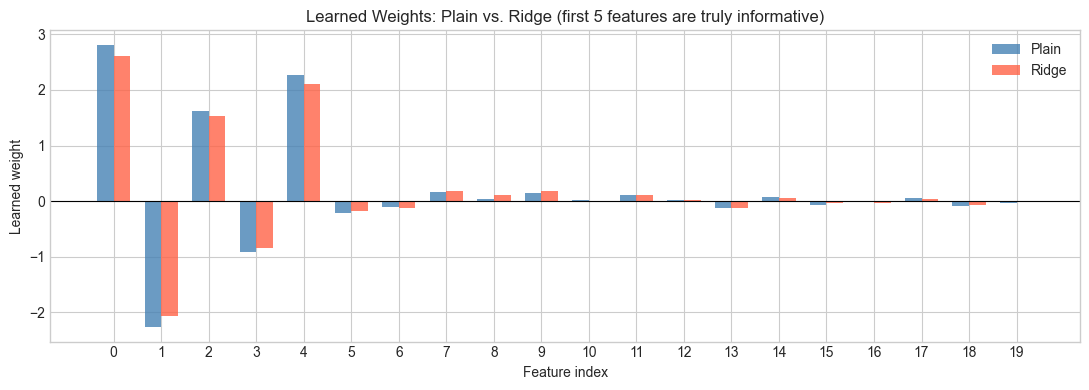

In [9]:
feature_idx = np.arange(n)

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.35
ax.bar(feature_idx - width/2, w_plain, width, label='Plain', color='steelblue', alpha=0.8)
ax.bar(feature_idx + width/2, w_ridge, width, label='Ridge', color='tomato',    alpha=0.8)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('Feature index')
ax.set_ylabel('Learned weight')
ax.set_title('Learned Weights: Plain vs. Ridge (first 5 features are truly informative)')
ax.legend()
ax.set_xticks(feature_idx)
plt.tight_layout()
plt.show()

## 12. Evaluation Metrics

In [10]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

results = {}
for name, w, b in [('Plain (λ=0)',  w_plain, b_plain),
                   ('Ridge (λ=10)', w_ridge, b_ridge)]:
    y_tr_pred = X_train_n @ w + b
    y_te_pred = X_test_n  @ w + b
    results[name] = {
        'Train MSE': mse(y_train, y_tr_pred),
        'Test  MSE': mse(y_test,  y_te_pred),
        'Train R²':  r2(y_train,  y_tr_pred),
        'Test  R²':  r2(y_test,   y_te_pred),
    }

print(f"{'Metric':<15}", end='')
for name in results:
    print(f"  {name:>15}", end='')
print()
print("-" * 50)
for metric in ['Train MSE', 'Test  MSE', 'Train R²', 'Test  R²']:
    print(f"{metric:<15}", end='')
    for name in results:
        print(f"  {results[name][metric]:>15.4f}", end='')
    print()

Metric               Plain (λ=0)     Ridge (λ=10)
--------------------------------------------------
Train MSE                 2.2182           2.3138
Test  MSE                 1.7672           1.7666
Train R²                  0.8945           0.8900
Test  R²                  0.9040           0.9040


## 13. Effect of λ on Test MSE

Iter     0 | Cost: 9.1669
Iter   500 | Cost: 1.1091
Iter  1000 | Cost: 1.1091
Iter  1500 | Cost: 1.1091
Iter  2000 | Cost: 1.1091
Iter  2500 | Cost: 1.1091
Iter     0 | Cost: 9.1669
Iter   500 | Cost: 1.1098
Iter  1000 | Cost: 1.1098
Iter  1500 | Cost: 1.1098
Iter  2000 | Cost: 1.1098
Iter  2500 | Cost: 1.1098
Iter     0 | Cost: 9.1669
Iter   500 | Cost: 1.1159
Iter  1000 | Cost: 1.1159
Iter  1500 | Cost: 1.1159
Iter  2000 | Cost: 1.1159
Iter  2500 | Cost: 1.1159
Iter     0 | Cost: 9.1674
Iter   500 | Cost: 1.1771
Iter  1000 | Cost: 1.1771
Iter  1500 | Cost: 1.1771
Iter  2000 | Cost: 1.1771
Iter  2500 | Cost: 1.1771
Iter     0 | Cost: 9.1697
Iter   500 | Cost: 1.4383
Iter  1000 | Cost: 1.4383


Iter  1500 | Cost: 1.4383


Iter  2000 | Cost: 1.4383
Iter  2500 | Cost: 1.4383
Iter     0 | Cost: 9.1726
Iter   500 | Cost: 1.7426
Iter  1000 | Cost: 1.7426
Iter  1500 | Cost: 1.7426
Iter  2000 | Cost: 1.7426
Iter  2500 | Cost: 1.7426
Iter     0 | Cost: 9.1955
Iter   500 | Cost: 3.5561
Iter  1000 | Cost: 3.5561
Iter  1500 | Cost: 3.5561
Iter  2000 | Cost: 3.5561
Iter  2500 | Cost: 3.5561
Iter     0 | Cost: 9.2242
Iter   500 | Cost: 4.9477
Iter  1000 | Cost: 4.9477
Iter  1500 | Cost: 4.9477
Iter  2000 | Cost: 4.9477
Iter  2500 | Cost: 4.9477
Iter     0 | Cost: 9.4536
Iter   500 | Cost: 8.3250
Iter  1000 | Cost: 8.3250
Iter  1500 | Cost: 8.3250
Iter  2000 | Cost: 8.3250
Iter  2500 | Cost: 8.3250


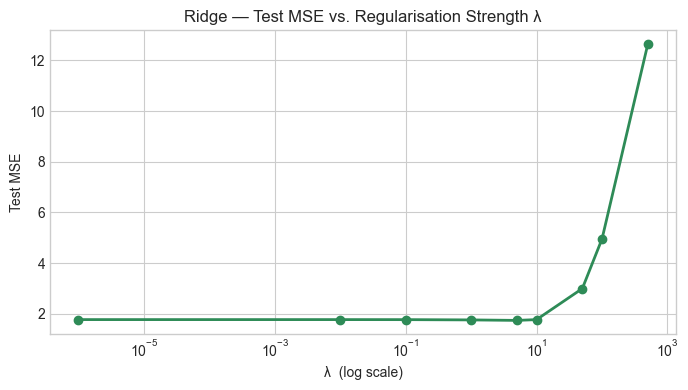

Best λ (by test MSE): 5


In [11]:
lambdas   = [0, 0.01, 0.1, 1, 5, 10, 50, 100, 500]
test_mses = []

for lam in lambdas:
    w_l, b_l, _ = gradient_descent_ridge(
        X_train_n, y_train, alpha=0.1, num_iters=3000, lambda_=lam)
    y_pred_l = X_test_n @ w_l + b_l
    test_mses.append(np.mean((y_test - y_pred_l) ** 2))

plt.figure(figsize=(7, 4))
plt.semilogx([l + 1e-6 for l in lambdas], test_mses,
             marker='o', color='seagreen', linewidth=2)
plt.xlabel('λ  (log scale)')
plt.ylabel('Test MSE')
plt.title('Ridge — Test MSE vs. Regularisation Strength λ')
plt.tight_layout()
plt.show()

best_lam = lambdas[int(np.argmin(test_mses))]
print(f"Best λ (by test MSE): {best_lam}")

## 14. Observations and Limitations

### What we observed
- Ridge shrinks the coefficients of the irrelevant features (indices 5–19) toward zero without eliminating them.
- The test MSE is lower for Ridge than for plain regression in the presence of irrelevant features — regularisation reduced overfitting.
- There is a sweet spot for $\lambda$; too large shrinks even the informative weights too much (underfitting).

### Limitations
| Limitation | Description |
|------------|-------------|
| **No feature selection** | Ridge shrinks weights but rarely sets them exactly to zero. Use Lasso (L1) for sparsity. |
| **λ requires tuning** | Cross-validation is needed to select the optimal $\lambda$. |
| **Still linear** | Ridge only addresses variance; it cannot capture non-linear relationships. |
| **Scale sensitivity** | Features must be normalised so the penalty is applied fairly across features. |
